# Utilities

In [1]:
save_knn_indexes = False
filter_by_knn_indexes = False

## Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import re, string, joblib, umap, time, pickle
import numpy as np
from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

# Visualization
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# Hierarchical clustering
from fastcluster import linkage
from scipy.cluster.hierarchy import dendrogram, fcluster
from scipy.spatial.distance import pdist

# Words cloud
from wordcloud import WordCloud

## Functions

In [3]:
# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    plt.show()

# Load data

In [4]:
data = pd.read_csv('../data/input/api/data_filtered.csv')
data.shape

(11244, 7)

In [5]:
df = pd.read_csv('../data/input/api/data_cleaned.csv')
df.shape

(11244, 4)

In [6]:
df_vectorized = pd.read_csv('../data/output/df_vectorized.csv')

In [7]:
if filter_by_knn_indexes:
    import json

    # Load the array from the JSON file
    with open('../data/output/knn_indices.json', 'r') as f:
        knn_indices = json.load(f)

    data = data.iloc[knn_indices].copy()
    df = df.iloc[knn_indices].copy()
    df_vectorized = df_vectorized.iloc[knn_indices].copy()

    data.reset_index(drop=True, inplace=True)
    df.reset_index(drop=True, inplace=True)
    df_vectorized.reset_index(drop=True, inplace=True)

In [8]:
X = df_vectorized.values
X.shape

(11244, 15867)

In [9]:
words2remove = []

In [10]:
vectorizer = joblib.load('../models/vectorizer.pkl')
words = vectorizer.get_feature_names_out()

Dimensionality reduction

Keep 95% of explained variance

In [11]:
explained_variance_ratio_goal = 0.95
pca = PCA(n_components=explained_variance_ratio_goal)
pca.fit(df_vectorized)
n_components = pca.n_components_
n_components

: 

: 

In [ ]:
X_original = X.copy()
df_vectorized_original = df_vectorized.copy()

# X = PCA(n_components=n_components).fit_transform(X) # Specify number of components
X = pca.transform(X) # Use fitted PCA with 95% of explained variance
df_vectorized = pd.DataFrame(X)

# Normalize
X = X / np.linalg.norm(X, axis=1, keepdims=True)
df_vectorized = pd.DataFrame(X)

NameError: name 'X' is not defined

In [ ]:
X_original.shape

(11244, 15867)

# KNN search

In [ ]:
n_neighbors = 500

knn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine', algorithm='brute').fit(X)

# Query text

query_text = "Artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks."
# query_text = "Control strategy, closed loop, nested control, submodules, capacitor voltage, circulating currents, common-mode voltage, current and voltage control, model predictive control, proportional-integral controller, modeling, total cluster and intercluster capacitor energy balancing, low-frequency oscillation mitigation."
# query_text = "Closed loop nested control strategies for intercluster energy balance and low-frequency oscillation mitigation with common-mode voltage and circulating currents."
# query_text = "Closed loop nested control strategies for intercluster energy balance and low-frequency oscillation mitigation."
# query_text = "Closed loop nested control strategies for intercluster energy balance."
# query_text = "Closed loop nested control strategies."
print(query_text)

# Preprocessing
query_text = [preprocess_text(query_text, words2remove)]
print(query_text)

# Vectorize
query_text_vec = vectorizer.transform(query_text).toarray()

# Dimensionality reduction
# query_text_vec = pca.transform(query_text_vec)

print(query_text_vec)

# Calculate KNNs
knn_distances, knn_idxs = knn.kneighbors(query_text_vec.reshape(1, -1))

for i, knn_idx in enumerate(knn_idxs[0]):
    display(f"Neighbor {i+1}, Index: {knn_idx}, Title: {data['title'][knn_idx]}")
    display(f"Abstract {data['html_url'][knn_idx]}: {data['abstract'][knn_idx]}")

Artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks.
['artificial intelligence deep learning imitation learning reinforcement learning neural network']
[[0. 0. 0. ... 0. 0. 0.]]


'Neighbor 1, Index: 2958, Title: application of neural network controller and policy gradient reinforcement learning on modular multilevel converter mmc a proof of concept'

'Abstract https://ieeexplore.ieee.org/document/9511045/: nowadays deep reinforcement learning method has been introduced to power electronic converter control but the current applications are relatively simple since the converter needing to be controlled has only a few variables applying the deep reinforcement learning method on the complicated converter with more variables has not been seen yet this paper shows that the reinforcement learning also has potential to control a complicated modular multilevel converter mmc in our method the capacitor voltages of submodules sms arm currents and output currents are directly sent to a neural network controller and the outputs of the controller are used as the gating signals of the sms directly the policy gradient pg based reinforcement learning algorithm is used without knowing any model information of the mmc after learning all the variables in the mmc can be well controlled i e the output current can track to the reference the capacitor vol

'Neighbor 2, Index: 10243, Title: state of charge soc balancing of battery modular multilevel management bm3 converter using q learning'

'Abstract https://ieeexplore.ieee.org/document/10173832/: this article presents a reinforcement learning rl algorithm for state of charge soc balancing of battery cells in a modular multilevel converter mmc system as converter topology the battery modular multilevel management bm3 topology is used a q learning algorithm is implemented and evaluated as a reinforcement learning algorithm the soc balancing of batteries in mmcs could be shown as an application area of rl up to seven bm3 modules can be balanced based on the proposed model the scalability of the model represents a limited applicability however the findings serve as a basis for further research in rl in the environment of mccs'

...

'Abstract https://ieeexplore.ieee.org/document/7425244/: this paper presents a complete analysis of a direct ac to ac modular multilevel converter direct mmc applied in medium voltage distribution networks through the soft open point concept the direct mmc is capable of bidirectional power flow between two feeders at any power factor even when the feeders have different nominal voltages and operate with a phase shift angle or unbalanced voltages the converter has six branches each one composed of full h bridges cells connected in series to generate a multilevel voltage waveform to share the blocking voltage of the power switches and to have fault tolerant operation this paper presents a suitable control scheme and provides a discussion about the capabilities and limitations of the converter the capacitor voltage balance control the efficiency and the power loss mitigation at various operation points simulation results and power loss calculations are presented for a three phase 11 kv 16

'Neighbor 499, Index: 7485, Title: modeling and experimental evaluation of z source modular multilevel converter using reduced inserted cells technique'

'Abstract https://ieeexplore.ieee.org/document/9548095/: the integration of a z source network with a modular multilevel converter mmc to provide voltage step up function is proposed in this paper the proposed z source modular multilevel converter zs mmc uses a z source network connected between the dc source and the dc link terminals of the mmc the operation principle of the zs mmc is presented utilising the reduced inserted cells rics modulation technique compared to the quasi zs mmc previously developed by the authors the zs mmc has small fundamental frequency component in the zs inductor current which requires a smaller inductor size for the z source network and is also more efficient the zs mmc is compared to other topologies that can accomplish buck and boost capabilities such as the quasi z source mmc the quasi z source cascaded multilevel converter and the full bridge based mmc to validate the viability of the proposed converter the operation of the zs mmc employing the rics te

'Neighbor 500, Index: 9580, Title: research on reduced order model of mmc grid connected system'

'Abstract https://ieeexplore.ieee.org/document/10353874/: with the development and promotion of new energy power generation technology power electronic equipment has become an important interface for new energy to access the distribution network and the number of power electronic equipment in the distribution network has soared however this also leads to the higher and higher order of the mathematical model of the distribution network which brings difficulties to the stability analysis of the system to solve this problem a nonlinear model reduction method of mmc grid connected inverter based on singular perturbation theory is proposed in this paper taking modular multilevel converter grid connected inverter as an example firstly the nonlinear model of mmc grid connected inverter including voltage and current sampling delay phase locked loop power outer loop and current inner loop is established by considering the coupling characteristics between the phase locked loop and other control 

In [ ]:
print(df['text'].str.contains('intelligence').sum())
print(df['text'].str.contains('artificial').sum())
print(df['text'].str.contains('deep').sum())
print(df['text'].str.contains('learning').sum())
print(df['text'].str.contains('neural').sum())
print(df['text'].str.contains('network').sum())

60
161
123
119
217
1748


In [ ]:
mask1 = df['text'].str.contains('intelligence')
mask2 = df['text'].str.contains('artificial')
mask3 = df['text'].str.contains('deep')
mask4 = df['text'].str.contains('learning')
mask5 = df['text'].str.contains('neural')
mask6 = df['text'].str.contains('network')

mask = (mask1 & mask2) | (mask3 & mask4) | (mask5 & mask6)
print(df[mask].shape)

(245, 4)


In [ ]:
knn_idxs.shape, np.array(df[mask].index).reshape(1, -1).shape

((1, 500), (1, 245))

In [ ]:
knn_idxs = np.array(df[mask].index).reshape(1, -1)

In [ ]:
data.iloc[knn_idxs[0]]

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
1,0,1 d convolutional neural networks for signal p...,electrocardiography two dimensional displays t...,20190417,1d convolutional neural networks cnns have rec...,223,https://ieeexplore.ieee.org/document/8682194/
181,0,a complete online solution of harmonic elimina...,harmonic analysis real time systems mathematic...,20230509,this paper proposes a novel online solution i ...,1,https://ieeexplore.ieee.org/document/10121774/
199,0,a comprehensive review of auto reclosing schem...,power system stability power transmission line...,20210506,the integration of distributed generators has ...,23,https://ieeexplore.ieee.org/document/9424595/
205,0,a comprehensive review of the protection metho...,protection methods multi terminal direct curre...,20220727,with the recent development in voltage source ...,0,https://ieeexplore.ieee.org/document/9841673/
216,0,a concurrent diagnosis method of igbt open cir...,circuit faults voltage measurement fault diagn...,20220922,the insulated gate bipolar transistor igbt is ...,21,https://ieeexplore.ieee.org/document/9899437/
...,...,...,...,...,...,...,...
11138,0,voltage estimation in combination with level a...,topology semiconductor diodes clamps switches ...,20221202,the modular multilevel converter mmc is a popu...,9,https://ieeexplore.ieee.org/document/9969159/
11178,0,vsc mt hvdc fault identification based on the ...,fault diagnosis voltage measurement statistica...,20231218,this paper presents a single ended protection ...,0,https://ieeexplore.ieee.org/document/10346558/
11186,0,wavelet threshold denoising based fault line d...,wavelet transforms fault diagnosis power engin...,20240710,the utilization of flexible dc transmission ha...,0,https://ieeexplore.ieee.org/document/10586579/
11229,0,zero emission marine vessels multidomain model...,adaptation models computational modeling emula...,20231129,proton exchange membrane fuel cells pemfcs are...,1,https://ieeexplore.ieee.org/document/10334432/


In [ ]:
if save_knn_indexes:
    import json

    # Save the index to a JSON file
    with open('../data/output/knn_indices.json', 'w') as f:
        json.dump(knn_idxs[0].tolist(), f)

# Dimensionality reduction

### PCA

In [ ]:
# # PCA 2D
# X_pca_2d = PCA(n_components=2).fit_transform(df_vectorized)
# df['pca2d_1'] = X_pca_2d[:, 0]
# df['pca2d_2'] = X_pca_2d[:, 1]

# # PCA 3D
# X_pca_3d = PCA(n_components=3).fit_transform(df_vectorized)
# df['pca3d_1'] = X_pca_3d[:, 0]
# df['pca3d_2'] = X_pca_3d[:, 1]
# df['pca3d_3'] = X_pca_3d[:, 2]

# # Graficar
# colors = np.ones(len(df))  # Color base
# colors_knn = np.zeros(len(df))  # Color para los KNN
# colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

# fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
#                     specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# # Puntos normales (fondo)
# fig.add_trace(
#     go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
#                marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                text=data['title'],
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos resaltados (delante)
# fig.add_trace(
#     go.Scatter(x=df.loc[knn_idxs[0], 'pca2d_1'], 
#                y=df.loc[knn_idxs[0], 'pca2d_2'], 
#                mode='markers',
#                marker=dict(color='red', size=5, opacity=1), 
#                text=data.loc[knn_idxs[0], 'title'], 
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos normales en 3D (fondo)
# fig.add_trace(
#     go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
#                  marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                  text=data['title'],
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# # Puntos resaltados en 3D (delante)
# fig.add_trace(
#     go.Scatter3d(x=df.loc[knn_idxs[0], 'pca3d_1'], 
#                  y=df.loc[knn_idxs[0], 'pca3d_2'], 
#                  z=df.loc[knn_idxs[0], 'pca3d_3'], 
#                  mode='markers',
#                  marker=dict(color='red', size=5, opacity=1), 
#                  text=data.loc[knn_idxs[0], 'title'], 
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
# fig.show()

### UMAP

In [ ]:
# n_neighbors = 200
# n_neighbors = int(len(df) / k)

# n_neighbors = 200
n_neighbors = 50 # 6.5x minutos, resultado: vision mas global, no se distinguen tanto los clusters
n_neighbors = 20 # 2.5x minutos, resultado: no se distinguen los clusters
n_neighbors = 10 # 1.5x minutos, resultado: puntos muy juntos, se distinguen los clusters
n_neighbors = 5 # x minutos, resultado: se distinguen bien los clusters, se ven un poco desconectados

min_dist = 0

# UMAP 2D
reducer_2d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=0, metric='cosine')
embedding_2d = reducer_2d.fit_transform(df_vectorized)
df['umap2d_1'] = embedding_2d[:, 0]
df['umap2d_2'] = embedding_2d[:, 1]

# UMAP 3D
reducer_3d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=3, random_state=0, metric='cosine')
embedding_3d = reducer_3d.fit_transform(df_vectorized)
df['umap3d_1'] = embedding_3d[:, 0]
df['umap3d_2'] = embedding_3d[:, 1]
df['umap3d_3'] = embedding_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[knn_idxs[0], 'umap2d_1'], 
               y=df.loc[knn_idxs[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[knn_idxs[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[knn_idxs[0], 'umap3d_1'],
                 y=df.loc[knn_idxs[0], 'umap3d_2'],
                 z=df.loc[knn_idxs[0], 'umap3d_3'],
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[knn_idxs[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## Plot KNN

In [ ]:
reduced_zero = reducer_2d.transform(np.zeros(df_vectorized.shape[1]).reshape(1, -1))
reduced_knn = reducer_2d.transform(df_vectorized.iloc[knn_idxs[0]])
reduced_query = reducer_2d.transform(query_text_vec)

knn_distances = knn_distances.flatten()
reduced_knn.shape, reduced_query.shape, knn_distances.shape, reduced_zero

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



((245, 2), (1, 2), (500,), array([[7.4615974, 5.0390964]], dtype=float32))

In [ ]:
knn_distances = knn_distances[::-1]

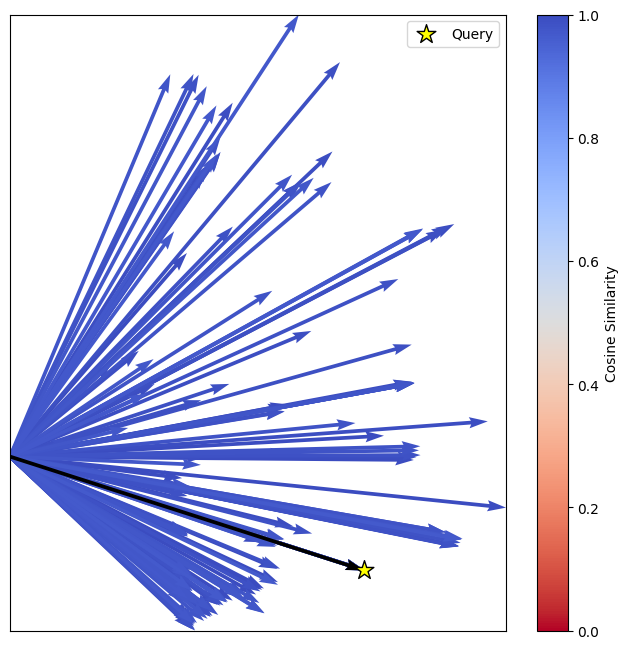

In [ ]:
# Asegúrate de que las distancias estén normalizadas entre 0 y 1
exp = 1
knn_distances_normalized = (knn_distances**exp - min(knn_distances**exp)) / (max(knn_distances**exp) - min(knn_distances**exp))

# Graficar
plt.figure(figsize=(8, 8))

# Crear un mapa de colores para las distancias normalizadas
norm = plt.Normalize(vmin=0, vmax=1)  # Normalización de las distancias
sm = plt.cm.ScalarMappable(cmap="coolwarm_r", norm=norm)  # Invertir el colormap con "coolwarm_r"
sm.set_array([])  # Necesario para que la barra de colores funcione

# 2. Graficar los vectores de los vecinos más cercanos (KNN)
for i in range(reduced_knn.shape[0]):
    knn_point = reduced_knn[i]
    color = sm.to_rgba(knn_distances_normalized[i])  # Obtener el color correspondiente a la distancia
    plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], knn_point[0], knn_point[1], angles='xy', scale_units='xy', scale=1, color=color)

# 1. Graficar el vector de consulta (query vector)
query_point = reduced_query[0]
plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], query_point[0], query_point[1], angles='xy', scale_units='xy', scale=1, color='black')
# Añadir una estrella para el vector de consulta (usamos plt.scatter)
plt.scatter(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 1]+query_point[1], color='yellow', s=200, marker='*', label='Query', edgecolors='black')

# Configuración del gráfico
# plt.gca().set_aspect('equal', adjustable='box')
# plt.title('Query Vector and KNN Vectors')
plt.autoscale(True)
# plt.xlabel('umap2d_1')
# plt.ylabel('umap2d_2')
plt.xticks([])
plt.yticks([])
plt.xlim([min(reduced_zero[0, 0], reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].min()), max(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].max())])
plt.ylim([min(reduced_zero[0, 1], reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].min()), max(reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].max())])
plt.legend()
plt.colorbar(sm, label='Cosine Similarity', ax=plt.gca())
plt.savefig('../data/output/knn.pdf', format='pdf')
plt.show()

# Clustering

## Hierarchical

In [ ]:
# methods = ['single', 'complete', 'average', 'weighted', 'centroid', 'ward']
# metrics = ['braycurtis', 'canberra', 'chebyshev', 'cityblock', 'correlation', 'cosine', 'dice', 'euclidean', 'hamming', 'jaccard', 'jensenshannon', 'kulczynski1', 'mahalanobis', 'matching', 'minkowski', 'rogerstanimoto', 'russellrao', 'seuclidean', 'sokalmichener', 'sokalsneath', 'sqeuclidean', 'yule']

methods = ['average', 'complete', 'weighted', 'ward']
metrics = ['cosine', 'jensenshannon', 'correlation']

method = 'ward'
metric = 'cosine'

In [ ]:
# Create hierarchical clustering with provided distance matrix
Z = linkage(X, method=method, metric=metric)

# Save clustering
joblib.dump(Z, '../data/output/hierarchical_cluster_Z.joblib')

: 

: 

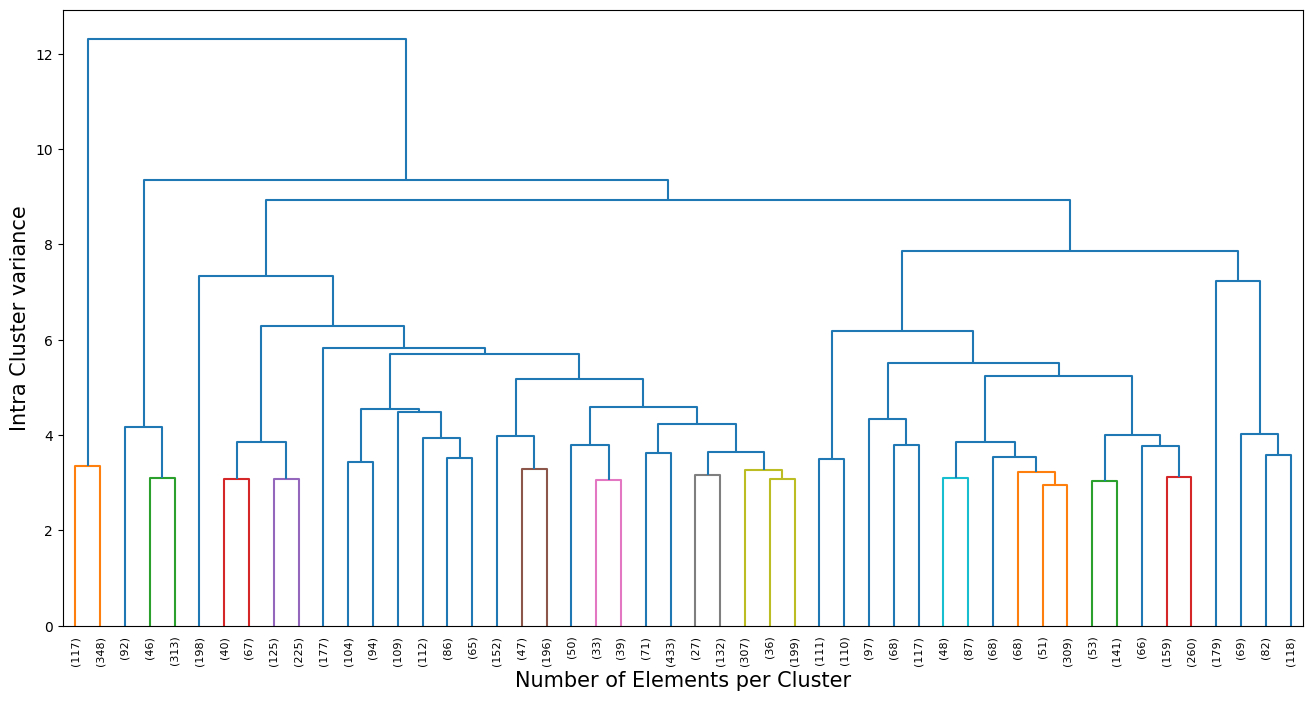

In [ ]:
# Load hierarchical clustering
Z = joblib.load('../data/output/hierarchical_cluster_Z.joblib')

# Plot
plt.figure(figsize=(16, 8))
# plt.title("Hierarchical clustering dendrogram")
# dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=4.96787729660)
dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=3.3553076382448)
plt.ylabel('Intra Cluster variance', size=15)
plt.xlabel('Number of Elements per Cluster', size=15)
plt.savefig('../data/output/dendrogram.pdf', format='pdf')
plt.show()

In [ ]:
# Extract threshold distances for each number of clusters
def get_threshold_distances(Z, k):
    # Extract distances from linkage matrix Z (third column)
    distances = np.sort(Z[:, 2])
    
    # La distancia umbral es la (n-k)-ésima distancia en el dendrograma
    n = Z.shape[0] + 1
    if k >= n:
        return 0  # Si k es igual o mayor al número de muestras, la distancia es mínima
    
    threshold_distance = distances[-(k-1)]
    return threshold_distance

# Rango de clusters deseado
cluster_range = range(3, 51)

# Diccionario para almacenar las distancias umbrales para cada número de clusters
threshold_distances = {k: get_threshold_distances(Z, k) for k in cluster_range}

# Mostrar las distancias umbrales para cada número de clusters
display(threshold_distances)


{3: 9.352299847114866,
 4: 8.939218309413238,
 5: 7.853391374374554,
 6: 7.331366040596648,
 7: 7.242183542033337,
 8: 6.2915978235874945,
 9: 6.189838386396069,
 10: 5.833813084358593,
 11: 5.705808730391593,
 12: 5.509529812515853,
 13: 5.248079173078542,
 14: 5.186919367446695,
 15: 4.585884101424093,
 16: 4.551029611472043,
 17: 4.477305399056089,
 18: 4.3425957456282935,
 19: 4.23299578327068,
 20: 4.1677504302005435,
 21: 4.018166741138986,
 22: 4.005532329698149,
 23: 3.9808206237742243,
 24: 3.940388729270169,
 25: 3.8646268615321193,
 26: 3.848846427932388,
 27: 3.794988236862993,
 28: 3.7903262733172793,
 29: 3.780136052057887,
 30: 3.6541507114333958,
 31: 3.6148993556610765,
 32: 3.57214884003498,
 33: 3.542910704858014,
 34: 3.5291899590657105,
 35: 3.4921354306663974,
 36: 3.4457521899083012,
 37: 3.3494550665615024,
 38: 3.2870619368941254,
 39: 3.2606821421591987,
 40: 3.2357694333124165,
 41: 3.1616995620001207,
 42: 3.1179672385883777,
 43: 3.1060428237808098,
 44: 3.

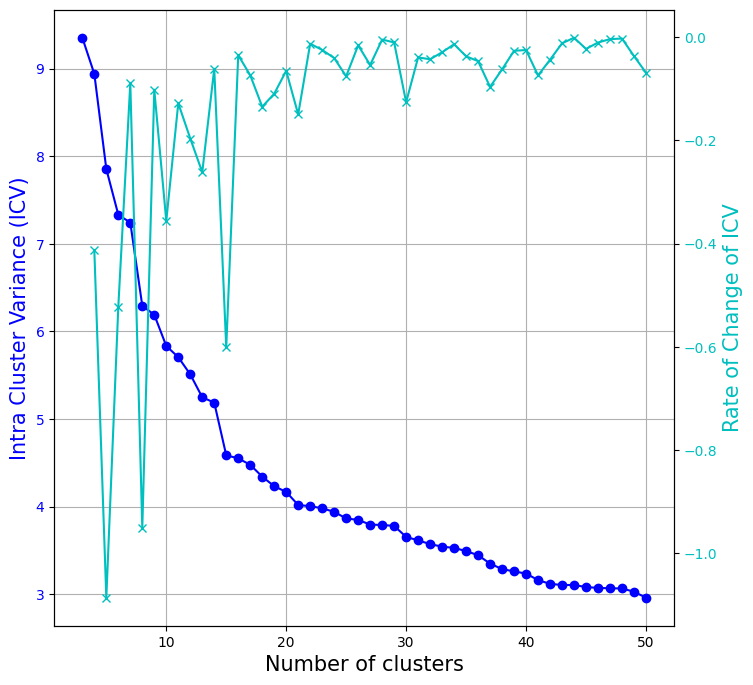

In [ ]:
k_range = np.array(list(threshold_distances.keys()))
distances = np.array(list(threshold_distances.values()))
distances_dff = np.diff(distances)

# Create figure
fig, ax1 = plt.subplots(figsize=(8, 8))

# Plot threshold distances
ax1.plot(k_range, distances, marker='o', color='b', label='Threshold Distance')
ax1.set_xlabel('Number of clusters', size=15)
ax1.set_ylabel('Intra Cluster Variance (ICV)', color='b', size=15)
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True)

# Plot rate of change of threshold distances
ax2 = ax1.twinx()
ax2.plot(k_range[1:], distances_dff, marker='x', color='c', label='Rate of Change of Threshold Distance')
ax2.set_ylabel('Rate of Change of ICV', color='c', size=15)
ax2.tick_params(axis='y', labelcolor='c')

# Show plot
# plt.title('Threshold Distance and Rate of Change')
plt.savefig('../data/output/elbow_method_hierarchical_clustering.pdf', format='pdf')
plt.show()

In [ ]:
# # Tune threshold for level selection for hierarchical conceptual map
# k_list_concpetual_map = k_range[np.where(distances_dff < -0.5)]
# k_list_concpetual_map

In [ ]:
# df_cluster = pd.DataFrame()

# df_cluster['clusters_1'] = 0

# for k in k_list_concpetual_map:
#     clusters_HC = fcluster(Z, k, criterion='maxclust') - 1
#     df_cluster[f'clusters_{k}'] = clusters_HC

# df_cluster['clusters_1'] = 0

# df_cluster

In [ ]:
# for col_idx, n_clusters in enumerate(df_cluster.columns):
#     for cluster in df_cluster[n_clusters].sort_values().unique():

#         df_topic = df_vectorized_original[df_cluster[n_clusters] == cluster]
#         centroid_words = summarize(df_topic, 5)
#         print(f'Cluster {cluster} ({df_topic.shape[0]}): {centroid_words}')

#         print(f' |---- Cluster {0}')
#     print('-'*100)

Elegir cantidad de tópicos

In [ ]:
k = 5
clusters = list(range(k))
print(clusters)

[0, 1, 2, 3, 4]


In [ ]:
# Asignar el cluster correspondiente
df['cluster_HC'] = fcluster(Z, k, criterion='maxclust') - 1
print(sorted(df['cluster_HC'].unique()))
df["cluster_HC"].value_counts()

[0, 1, 2, 3, 4]


cluster_HC
2    3124
3    1813
0     465
1     451
4     448
Name: count, dtype: int64

## Kmeans

### Metodo del codo

In [ ]:
# # Listas para almacenar la inercia y el Silhouette Score de cada k
# inertia = []
# silhouette_scores = []

# # Rango de k para probar
# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Calcular la inercia y el Silhouette Score para cada valor de k
# for k_value in k_range:
#     print(f"Comenzando KMeans para k={k_value}")
#     tic = time.time()

#     kmeans = KMeans(n_clusters=k_value, random_state=0, n_init=100, init='k-means++', max_iter=100)
#     kmeans.fit(X)
    
#     # Almacenar la inercia
#     inertia.append(kmeans.inertia_)
    
#     # Calcular el Silhouette Score y almacenarlo
#     score = silhouette_score(X, kmeans.labels_)
#     silhouette_scores.append(score)
    
                                
#     toc = time.time()
#     print(f"Completado en {toc - tic:.2f} segundos\n")

# # Guardar
# with open('data/output/kmeans_metrics.pkl', 'wb') as f:
#     pickle.dump({'inertia': inertia, 'silhouette_scores': silhouette_scores}, f)

# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Cargar
# with open('data/output/kmeans_metrics.pkl', 'rb') as f:
#     metrics = pickle.load(f)
# inertia = metrics['inertia']
# silhouette_scores = metrics['silhouette_scores']

# # Calcular la tasa de cambio para la inercia y el Silhouette Score
# delta_inertia = np.diff(inertia)
# delta_silhouette = np.diff(silhouette_scores)

# # Crear una figura con dos subgráficos (lado a lado)
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# # Graficar la inercia en el primer subgráfico (izquierda)
# ax1.plot(k_range, inertia, marker='o', color='b', label='Inercia')
# ax1.set_xlabel('Número de clusters (k)')
# ax1.set_ylabel('Inercia', color='b')
# ax1.tick_params(axis='y', labelcolor='b')

# # Graficar la tasa de cambio de la inercia en el eje y derecho
# ax1_twin = ax1.twinx()
# ax1_twin.plot(k_range[1:], delta_inertia, marker='x', color='c', label='Tasa de cambio de Inercia')
# ax1_twin.set_ylabel('Tasa de cambio de Inercia', color='c')
# ax1_twin.tick_params(axis='y', labelcolor='c')

# # Título y leyenda para el primer gráfico
# ax1.set_title('Inercia y Tasa de Cambio de Inercia')
# # ax1.legend(loc='best')

# # Graficar el Silhouette Score en el segundo subgráfico (derecha)
# ax2.plot(k_range, silhouette_scores, marker='o', color='g', label='Silhouette Score')
# ax2.set_xlabel('Número de clusters (k)')
# ax2.set_ylabel('Silhouette Score', color='g')
# ax2.tick_params(axis='y', labelcolor='g')

# # Graficar la tasa de cambio del Silhouette Score en el eje y derecho
# ax2_twin = ax2.twinx()
# ax2_twin.plot(k_range[1:], delta_silhouette, marker='x', color='y', label='Tasa de cambio de Silhouette Score')
# ax2_twin.set_ylabel('Tasa de cambio de Silhouette Score', color='y')
# ax2_twin.tick_params(axis='y', labelcolor='y')

# # Título y leyenda para el segundo gráfico
# ax2.set_title('Silhouette Score y Tasa de Cambio de Silhouette Score')
# # ax2.legend(loc='best')

# # Mostrar el gráfico
# plt.tight_layout()  # Ajusta el espacio entre los subgráficos
# plt.show()

### Clustering final

In [ ]:
# kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100).fit(X)
# df["cluster_KM"] = kmeans.predict(X)

# print(sorted(df['cluster_KM'].unique()))
# df["cluster_KM"].value_counts()

Clasificación de un texto

In [ ]:
# predicted_cluster = kmeans.predict(topico_vec)
# print(predicted_cluster)

## Results

In [ ]:
# Pintar los KNN del topico consultado
# df.loc[indices_knn[0], "cluster_HC"] = -1
# df.loc[indices_knn[0], "cluster_KM"] = -1

Choose clustering type:
* cluster_HC
* cluster_KM

In [ ]:
# Select clsutering method
clustering_method = "cluster_HC"

# Convert clsuter column to categorical type
df[clustering_method] = df[clustering_method].astype('category')

In [ ]:
# # PCA

# # Calcular centroides de cada cluster
# centroids = df.groupby(clustering_method)[['pca2d_1', 'pca2d_2']].mean().reset_index()

# # Crear gráfico de dispersión interactivo con leyenda discreta
# fig = px.scatter(
#     df, 
#     x='pca2d_1',
#     y='pca2d_2',
#     size=None,
#     color=clustering_method,  # Usar la columna categórica para el color
#     title='PCA 2D',
#     color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
#     hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
#     hover_name='title',  # Mostrar el título como identificador principal en el tooltip
#     opacity=0.5,
#     category_orders={clustering_method: clusters}
# )

# # Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
# fig.update_layout(
#     xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
#     yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
#     width=800,  # Establece un tamaño específico para el ancho
#     height=600,  # Establece el mismo tamaño para la altura
#     legend_title_text='Cluster'  # Personalizar el título de la leyenda
# )

# # Personalizar el formato del tooltip
# fig.update_traces(
#     marker=dict(size=5),
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
#                   "<b>X:</b> %{x}<br>" +  # Coordenada X
#                   "<b>Y:</b> %{y}<br>" +  # Coordenada Y
#                   "<extra></extra>"  # Eliminar información adicional no deseada
# )

# # Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
# fig.add_scatter(
#     x=df.loc[knn_idxs[0], 'pca2d_1'],
#     y=df.loc[knn_idxs[0], 'pca2d_2'],
#     mode='markers',
#     marker=dict(color='red', size=10, line=dict(color='black', width=2)),
#     name='KNNs',
#     showlegend=True,
#     customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
#     hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +
#                   "<b>X:</b> %{x}<br>" +
#                   "<b>Y:</b> %{y}<br>" +
#                   "<extra></extra>"
# )

# # Obtener los colores usados en el gráfico principal
# colors = px.colors.qualitative.Alphabet

# # Crear un diccionario que mapea cada cluster a un color
# cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# # Agregar centroides con el color correspondiente de su cluster
# for cluster in centroids[clustering_method]:
#     centroid = centroids[centroids[clustering_method] == cluster]
#     fig.add_scatter(
#         x=centroid['pca2d_1'],
#         y=centroid['pca2d_2'],
#         mode='markers',
#         marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
#         name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
#         showlegend=False
#     )

# # Mostrar el gráfico
# fig.show()

In [ ]:
# UMAP 2D

# Calcular centroides de cada cluster
centroids = df.groupby(clustering_method)[['umap2d_1', 'umap2d_2']].mean().reset_index()

custom_colors = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", 
    "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf", "#f6a828"
]

custom_colors = custom_colors[:len(clusters)]

# Crear gráfico de dispersión interactivo
fig = px.scatter(
    df, 
    x='umap2d_1',
    y='umap2d_2',
    size=None,
    color=clustering_method,
    color_discrete_sequence=custom_colors,
    hover_data=[clustering_method, 'title'],
    hover_name='title',
    opacity=0.7,
    category_orders={clustering_method: clusters}
)

# Fondo blanco, grilla visible y ejes definidos
fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white',
    xaxis=dict(
        title='umap2d_1',
        showgrid=True,
        gridcolor='lightgray',
        gridwidth=1,
        zeroline=False,
        scaleanchor="y"
    ),
    yaxis=dict(
        title='umap2d_2',
        showgrid=True,
        gridcolor='lightgray',
        gridwidth=1,
        zeroline=False,
        scaleanchor="x"
    ),
    width=800,
    height=800,
    legend_title_text='Cluster',
    legend_title_font_size=20,  # Tamaño más grande para el título de la leyenda
    legend_font_size=18,        # Tamaño más grande para el texto de la leyenda
    legend_tracegroupgap=10,    # Espaciado entre grupos de leyenda
    legend_traceorder='normal', # Orden normal de leyenda
    legend_itemwidth=30,        # Ancho de los elementos de la leyenda
    legend_itemsizing='constant' # Mantener el tamaño de los símbolos constante
)

# Personalizar el formato del tooltip
fig.update_traces(
    marker=dict(size=5),
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Agregar puntos resaltados (KNNs) en rojo
fig.add_scatter(
    x=df.loc[knn_idxs[0], 'umap2d_1'],
    y=df.loc[knn_idxs[0], 'umap2d_2'],
    mode='markers',
    marker=dict(color='red', size=10, line=dict(color='black', width=2)),
    name='KNNs',
    showlegend=True,
    customdata=df.loc[knn_idxs[0], [clustering_method]],
    hovertext=df.loc[knn_idxs[0], 'title'],
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Asociar colores a cada cluster
cluster_colors = dict(zip(df[clustering_method].cat.categories, custom_colors))

# Agregar centroides con los colores correspondientes
for cluster in centroids[clustering_method]:
    centroid = centroids[centroids[clustering_method] == cluster]
    fig.add_scatter(
        x=centroid['umap2d_1'],
        y=centroid['umap2d_2'],
        mode='markers',
        marker=dict(color=cluster_colors[cluster], size=12, symbol='x', line=dict(color='black', width=2)),
        name=f'Centroid {cluster}',
        showlegend=False
    )

# Guardar gráfico como PDF

fig.update_layout(
    margin=dict(l=0, r=0, t=0, b=0)  # l = left, r = right, t = top, b = bottom
)

fig.write_image("../data/output/UMAP.pdf")

# Mostrar gráfico
fig.show()

C:\Users\Ingeniería Eléctrica\AppData\Local\Temp\ipykernel_7728\2699728427.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [ ]:
df

,title,index_terms,abstract,text,umap2d_1,umap2d_2,umap3d_1,umap3d_2,umap3d_3,cluster_HC
0,2 terminal hybrid hvdc cost effective alternat...,hvdc transmission voltage control circuit faul...,2 terminal hybrid hvdc consisting of a line co...,terminal hybrid hvdc cost effective alternativ...,11.419662,8.427659,9.732146,6.994794,5.181221,3
1,20 mw level offshore wind power converter base...,switching converters multilevel converters cap...,with the development of offshore wind turbines...,mw level offshore wind power converter based s...,9.177103,13.134144,12.565406,9.547594,6.075575,0
2,21 level csd based solar multilevel inverter f...,photovoltaic systems induction motor drives he...,as the demand for electricity increases renewa...,level csd based solar multilevel inverter fed ...,16.475756,5.930287,14.875982,3.549511,4.637675,2
3,2n 1 selective harmonic elimination pwm for mo...,switches harmonic analysis pulse width modulat...,the performance of modular multilevel converte...,n selective harmonic elimination pwm modular m...,13.523825,5.071999,7.211762,1.071877,0.954523,2
4,3 phase high gain pfc converter implementing s...,switches capacitors rectifiers harmonic analys...,in this paper a novel topology of three phase ...,phase high gain pfc converter implementing swi...,6.089883,3.749470,5.896386,4.242725,4.230858,2
...,...,...,...,...,...,...,...,...,...,...
6296,zero sequence voltage suppression control with...,voltage control capacitors matrix converters a...,zero sequence voltage suppression control for ...,zero sequence voltage suppression control capa...,8.865499,0.697318,11.088027,2.920965,1.160986,2
6297,zero voltage switching double wing multilevel ...,voltage control capacitors switches inductance...,this paper presents a phase shift control meth...,zero voltage switching double wing multilevel ...,6.116014,3.831943,6.020819,4.336548,4.278245,2
6298,zpuc a new configuration of single dc source f...,topology capacitors multilevel converters swit...,z packed u cell zpuc converter topology is pre...,zpuc new configuration single dc source modula...,11.788444,2.416918,8.520548,1.807159,2.724940,2
6299,zpuc mmc real time implementation with model p...,multilevel converters capacitors power control...,with reduced number of components count modula...,zpuc mmc real time implementation model predic...,11.204374,-2.961511,12.775820,2.903144,-0.858562,2


In [ ]:
nk = df.loc[knn_idxs[0], 'cluster_HC'].value_counts().sort_index()
nk

cluster_HC
0     3
1     5
2    28
3    60
4     4
Name: count, dtype: int64

In [ ]:
nk/knn_idxs.shape[1]

cluster_HC
0    0.03
1    0.05
2    0.28
3    0.60
4    0.04
Name: count, dtype: float64

In [ ]:
Ck = df['cluster_HC'].value_counts().sort_index()
Ck

cluster_HC
0     465
1     451
2    3124
3    1813
4     448
Name: count, dtype: int64

In [ ]:
Ck/df.shape[0]

cluster_HC
0    0.073798
1    0.071576
2    0.495794
3    0.287732
4    0.071100
Name: count, dtype: float64

In [ ]:
(nk/knn_idxs.shape[1]) / (Ck/df.shape[0])

cluster_HC
0    0.406516
1    0.698559
2    0.564750
3    2.085273
4    0.562589
Name: count, dtype: float64

# Summarization
Importantest words by Tf-Idf score

In [ ]:
def summarize(df_topic, n_centroid_words):

    # Find centroid
    centroid = df_topic.mean(axis=0)

    # Take the n first words
    centroid_words = ", ".join([words[idx] for idx in centroid.argsort()[::-1][:n_centroid_words]])
    
    # To list, remove duplicated words
    centroid_words = centroid_words.replace(',','').split(' ')
    centroid_words_temp = []
    for word in centroid_words:
        if word not in centroid_words_temp:
            centroid_words_temp.append(word)
    centroid_words = centroid_words_temp
    
    return centroid_words

### Corpus

In [ ]:
df_topic = df_vectorized_original.copy()
centroid_words = summarize(df_topic, 10)
print(f'Full corpus: {centroid_words}')

# word_cloud(centroid_words)

Full corpus: ['voltage', 'control', 'converter', 'power', 'current', 'dc', 'system', 'multilevel', 'mmc', 'fault']


### Clusters

In [ ]:
for cluster in clusters:
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 20)
    print(f'Cluster {cluster}: {", ".join(centroid_words)}')

    # word_cloud(centroid_words)

Cluster 0: wind, offshore, farm, power, voltage, control, turbine, energy, system, hvdc, dc, converter, grid, fault, transmission, current, ac, frequency, high, generator
Cluster 1: fault, voltage, dc, current, protection, circuit, control, converter, system, mmc, line, hvdc, power, tolerant, short, ac, transmission, multilevel, breaker, strategy
Cluster 2: voltage, control, converter, current, power, dc, capacitor, multilevel, modulation, frequency, modular, switching, high, mmc, harmonic, arm, balancing, phase, method, level
Cluster 3: control, voltage, power, system, converter, model, dc, current, grid, stability, mmc, hvdc, ac, energy, multilevel, loop, frequency, high, impedance, modular
Cluster 4: battery, photovoltaic, power, storage, voltage, energy, converter, system, control, pv, grid, dc, vehicle, solar, charge, multilevel, electric, inverter, current, maximum


# Hierarchical conceptual map

In [ ]:
# import networkx as nx

# # Crear el grafo dirigido
# G = nx.DiGraph()

# # Ejemplo de títulos y niveles de clusters
# niveles = {
#     0: [],
#     1: ["Cluster A", "Cluster B", "Cluster C"],
#     2: ["Cluster A1", "Cluster A2", "Cluster B1", "Cluster B2", "Cluster C1"]
# }

# # Conectar los niveles de clusters
# relaciones = [
#     ('\n'.join(centroid_words), "Cluster A"),
#     ('\n'.join(centroid_words), "Cluster B"),
#     ('\n'.join(centroid_words), "Cluster C"),
#     ("Cluster A", "Cluster A1"),
#     ("Cluster A", "Cluster A2"),
#     ("Cluster B", "Cluster B1"),
#     ("Cluster B", "Cluster B2"),
#     ("Cluster C", "Cluster C1")
# ]

# # Agregar nodos y aristas al grafo
# for nivel in niveles.values():
#     G.add_nodes_from(nivel)
# G.add_edges_from(relaciones)

# # Asignar posiciones centradas a los nodos
# pos = {}
# max_width = max(len(nodos) for nodos in niveles.values())

# for nivel, nodos in niveles.items():
#     offset = (max_width - len(nodos)) / 2
#     for i, nodo in enumerate(nodos):
#         pos[nodo] = (i + offset, -nivel)

# # Dibujar el mapa conceptual jerárquico
# plt.figure(figsize=(8, 6))
# nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue', font_size=10, font_weight='bold', edge_color='gray')
# plt.title("Mapa Conceptual Jerárquico")
# plt.show()

# Documento representativo
En corpus completo y por clusters

## Centroides

In [ ]:
def encontrar_mas_cercano_al_centroide(df_vectorized, data):
    centroide = df_vectorized.mean(axis=0)
    distancias = euclidean_distances(df_vectorized, [centroide])
    indice_mas_cercano = np.argmin(distancias)
    texto_mas_cercano = data.iloc[indice_mas_cercano]['abstract']
    titulo = data.iloc[indice_mas_cercano]['title']
    return titulo, texto_mas_cercano

### Corpus

In [ ]:
titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(df_vectorized, data)
display(f"Texto mas representativo del corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {texto_mas_cercano}")

'Texto mas representativo del corpus:'

'Título: evolution of topologies modeling control schemes and applications of modular multilevel converters'

'Abstract: modular multilevel converter mmc is one of the most promising topologies for medium to high voltage high power applications the main features of mmc are modularity voltage and power scalability fault tolerant and transformer less operation and high quality output waveforms over the past few years several research studies are conducted to address the technical challenges associated with the operation and control of the mmc this paper presents the development of mmc circuit topologies and their mathematical models over the years also the evolution and technical challenges of the classical and model predictive control methods are discussed finally the mmc applications and their future trends are presented'

### Clusters

In [ ]:
data.shape

(6301, 7)

In [ ]:
for cluster in clusters:
    cluster_data_vectorized = df_vectorized.loc[(df[clustering_method] == cluster).values]
    cluster_data = data[df[clustering_method] == cluster]
    titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(cluster_data_vectorized, cluster_data)
    display(f"Cluster {cluster}: Texto mas cercano al centroide")
    display(f"Título: {titulo}")
    display(f"Abstract: {texto_mas_cercano}")

'Cluster 0: Texto mas cercano al centroide'

'Título: control and modelling of offshore wind farms using high capacity wind generators and mmc hvdc transmission'

'Abstract: modular multi level converter based high voltage direct current mmc hvdc technology and high capacity wind generators have emerged as a leading solution for offshore wind power transmission this paper proposes a control strategy for 66kv10mw wind turbines and the mmc and constructs a comprehensive model of the offshore wind power transmission system the effectiveness of the control scheme is then verified through transient simulation the proposed control strategy ensures the stability of the wind farm side ac voltage frequency and dc voltage while also allowing for flexible adjustments to the amount of reactive power output to the ac power grid'

'Cluster 1: Texto mas cercano al centroide'

'Título: research on the fault characteristics of hvdc based on modular multilevel converter'

...

'Título: analysis and improvement of the ac voltage control of gfm mmc to improve the voltage stability of ac dc hybrid power grid'

'Abstract: the grid forming control is regarded as an effective solution for grid tied converters to operate under weak grid conditions currently most of the grid forming control strategies are designed for 2 level voltage source converters the power loop ac voltage loop ac current loop control is usually adopted in these strategies this control structure highly relies on the ac side filter capacitor however in high voltage situations the modular multilevel converter which has no ac side filter capacitor is commonly adopted the integral effect of the filter capacitor in the original control path is replaced by the differential effect of the grid impedance which worsens the performance of ac voltage control to solve this problem the steady state model of mmc using grid forming control is established based on this model two improved ac voltage control strategies are proposed in this paper simulation results in pscad emtdc show that the proposed control realizes desired dynamic control of

'Cluster 4: Texto mas cercano al centroide'

'Título: pv integrated modular multilevel converter based battery energy storage system'

'Abstract: the need for auxiliary services and the growing use of distributed generation with renewable energy sources drive the use of battery energy storage systems bess in micro grids and smart grids this paper focuses on the mathematical model and power flow control of pv integrated modular multilevel converter pv mmc with bess the study of pv integrated mmcbess can be seen as a three terminal network dc bus connected pv array ac side of the grid or load and each sub module access to battery storage moreover through the ac and dc side current control the free flow of three terminal energy is attained according to mathematical modeling and analysis the control method of ac and pv side is obtained and discharging and charging control of batteries is realized by controlling the ac and pv side power power control as the fundamental the balancing control of bes is also studied in detail phase phase and intra phase balance control strategies are tested in matlab simulink'

## Puntaje Tfidf
Le llamaremos representante al abstract que tenga una mayor cantidad de frecuencia acumulada de palabras del tfid vectorizer, ya que eso implica una mayor participación (profundizar).

Disclaimer: Tenía razón en dudad del método. esto en verdad lo k hace es elegir al que tiene mayor interaccion entre palabras, es decir, el abstract mas complejo.

### Corpus

In [ ]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
display("Texto más representativo del corpus:")
display(f"Título: {data['title'].iloc[abstract00]}")
display(f"Abstract: {data['abstract'].iloc[abstract00]}")

'Texto más representativo del corpus:'

'Título: transformation of the energy system in germany enhancement of system stability by integration of innovative multilevel hvdc in the ac grid'

'Abstract: globally deregulation and privatization are posing new challenges on high voltage transmission and on distribution systems as well an increasingly liberalized market will encourage trading opportunities to be identified and developed environmental constraints such as energy saving and co2 reduction also play an important role the loading of existing power systems will further increase leading to bottlenecks and reliability problems consequently we have to deal with an area of conflicts between reliability of supply environmental sustainability as well as economic efficiency furthermore in germany the transition from well proven energy mix to the new energy transition energie wende with large amounts of volatile regenerative energy sources res e g over 30 gw solar power on medium and even low voltage level in combination with over 30 gw of wind power at present mainly onshore plus high amounts of offshore wind power in the future 30 to 50 gw long term in combination with the 

### Clusters

In [ ]:
for cluster in clusters:
    abstract00 = df_vectorized.loc[(df[clustering_method] == cluster).values].sum(axis=1).sort_values(ascending=False).index[0]
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    display(f"Cluster {cluster}: {centroid_words}")
    display(f"Título: {data['title'].iloc[abstract00]}")
    display(f"Abstract: {data['abstract'].iloc[abstract00]}")

"Cluster 0: ['wind', 'offshore', 'farm', 'power', 'voltage', 'control', 'turbine', 'energy', 'system', 'hvdc']"

'Título: study on fault ride through capability of wind farm integration using mmc hvdc'

'Abstract: due to various advantages high voltage direct current transmission based on voltage source converter vsc hvdc is gradually coming into practice it realizes the independent control of both active and reactive power and has a good dynamic ability of reactive power support moreover if used in wind power transmission vsc hvdc decouples the wind farm and the ac grid which effectively enhances the fault ride through frt capability of wind power system there are mainly three vsc circuits for hvdc application at present hvdc light of abb hvdc plus of simens and alternate arm multilevel converter a2mc of alstom schemes from abb and simens have been widely used which both apply vsc for ac dc conversion hvdc light uses two level converter with serial structure of insulated gate bipolar transistors igbt which has advantages like small volume light weight and simple control of converter arm however it also has some disadvantages such as more switching loss higher harmonics in output powe

"Cluster 1: ['fault', 'voltage', 'dc', 'current', 'protection', 'circuit', 'control', 'converter', 'system', 'mmc']"

'Título: aspects of hvdc breakers in hvdc energy transmission systems based on self commutated converter systems'

...

'Título: transformation of the energy system in germany enhancement of system stability by integration of innovative multilevel hvdc in the ac grid'

'Abstract: globally deregulation and privatization are posing new challenges on high voltage transmission and on distribution systems as well an increasingly liberalized market will encourage trading opportunities to be identified and developed environmental constraints such as energy saving and co2 reduction also play an important role the loading of existing power systems will further increase leading to bottlenecks and reliability problems consequently we have to deal with an area of conflicts between reliability of supply environmental sustainability as well as economic efficiency furthermore in germany the transition from well proven energy mix to the new energy transition energie wende with large amounts of volatile regenerative energy sources res e g over 30 gw solar power on medium and even low voltage level in combination with over 30 gw of wind power at present mainly onshore plus high amounts of offshore wind power in the future 30 to 50 gw long term in combination with the 

"Cluster 4: ['battery', 'photovoltaic', 'power', 'storage', 'voltage', 'energy', 'converter', 'system', 'control', 'pv']"

'Título: interfacing an electric vehicle to the grid with modular conversion unit a case study of a charging station and its control framework'

'Abstract: in response to vehicle to grid v2g application promising solutions for fast charging stations of electric vehicles ev are still demanding with considerations of their interfaced requirements on the ac distribution network an integrating periodic loads with different energy storage technologies to the common dc bus is strong alternative to the existing infrastructures this paper addresses a key role of rectification topology in fast charging stations with respect to higher scalability redundancy and its capacity to compensate unbalanced loads or total harmonic distortion thd at the point of common coupling pcc it is achieved through the operational performance of the modular multilevel converter mmc deployed to transfer ac power generated by medium voltage grid to common dc bus feeding multiple ev batteries the developed control framework is constructed by two layer configuration in which a first layer finite control set model predictive control fcs mpc methodology provides a

## Similaridad del coseno

### Corpus

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def RepresentanteCoseno(matrix_vectors):
    """
    Retorna el índice del texto más representativo del conjunto (más similar al resto).
    
    Parameters:
    - matrix_vectors: matriz (numpy array o pandas DataFrame) donde cada fila es un vector (TF-IDF o embedding)
    
    Returns:
    - Índice del texto más representativo
    """
    # Asegura que sea array de NumPy
    if hasattr(matrix_vectors, 'values'):
        matrix_vectors = matrix_vectors.values

    # Calcular matriz de similitud coseno
    similitudes = cosine_similarity(matrix_vectors)
    
    # Sumar similitudes por fila (suma de cada vector con todos los demás)
    suma_similitudes = np.sum(similitudes, axis=1)
    
    # Retornar índice del vector con mayor similitud total
    return np.argmax(suma_similitudes)


In [ ]:
abstract00 = RepresentanteCoseno(df_vectorized)
titulo = data["title"].iloc[abstract00]
abstract_mas_representativo = data["abstract"].iloc[abstract00]

display(f"Texto mas similar a todos los demas en el corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {abstract_mas_representativo}")

'Texto mas similar a todos los demas en el corpus:'

'Título: evolution of topologies modeling control schemes and applications of modular multilevel converters'

'Abstract: modular multilevel converter mmc is one of the most promising topologies for medium to high voltage high power applications the main features of mmc are modularity voltage and power scalability fault tolerant and transformer less operation and high quality output waveforms over the past few years several research studies are conducted to address the technical challenges associated with the operation and control of the mmc this paper presents the development of mmc circuit topologies and their mathematical models over the years also the evolution and technical challenges of the classical and model predictive control methods are discussed finally the mmc applications and their future trends are presented'

### Clusters

In [ ]:
for cluster in clusters:
    abstract00 = RepresentanteCoseno(df_vectorized.loc[(df[clustering_method] == cluster).values])
    titulo = data["title"].iloc[abstract00]
    abstract_mas_representativo = data["abstract"].iloc[abstract00]
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    display(f"Cluster {cluster}: {centroid_words}")
    display(f"Título: {titulo}")
    display(f"Abstract: {abstract_mas_representativo}")

"Cluster 0: ['wind', 'offshore', 'farm', 'power', 'voltage', 'control', 'turbine', 'energy', 'system', 'hvdc']"

'Título: a control strategy of photovoltaic grid connected inverter based on active power reserve'

'Abstract: now a days photovoltaic pv power are getting more and more widespread with the increase in the energy demand and the concern for the environmental pollution around the world with the continuous increase of pv grid connected power its frequency are mainly supported by the grid but it provides almost no rotational inertia to the grid the cascaded h bridge chb converter is a suitable candidate for the grid interconnection due to its modular characteristics high quality output waveforms and capability of connecting to medium voltage grids without transformers a control strategy with the function of supporting the grid frequency based on active power reserve is proposed in this paper for the three phase chb pv grid connected system without the need for energy storage a proportion of the total pv power is reserved by the selected reserved cells to provide the power buffer for grid frequency supporting meanwhile by using the proposed method of reserve power distribution among the p

"Cluster 1: ['fault', 'voltage', 'dc', 'current', 'protection', 'circuit', 'control', 'converter', 'system', 'mmc']"

'Título: a medium voltage three stage power converter topology for distribution grid scale energy storage systems'

...

'Título: a high voltage gain capable mmc for offshore wind farms frequency component analysis and minimization of capacitor voltage ripple'

'Abstract: modular multilevel converter mmc and hvdc technology together provide an indispensable solution to integrate offshore wind farms with onshore ac grid however the bulky size of mmc and voltage boosting transformers vbts pose a big challenge to keep the footprint and cost of the onshore platform low with this background a full bridge submodule sm modified mmc and a suitably modified switching function are proposed which utilize the negative sm voltage to achieve ac side voltage boosting how much negative sm voltages are to be applied across the arms is determined by the group submodule ratio gsr parameter introduced in the switching function the acquired boosting ability not only shrinks the voltage boosting requirement of vbts but also reduces the semiconductor switches upto 10 and or the sm count 8 30 analytical solutions derived for the sm capacitor sizing are also presented the analysis is further utilized to obtain a novel circulating current injection scheme ccis which u

"Cluster 4: ['battery', 'photovoltaic', 'power', 'storage', 'voltage', 'energy', 'converter', 'system', 'control', 'pv']"

'Título: a magnetically controlled bridge arm reactor topology design for mmc applications'

'Abstract: a bridge arm reactor is a type of reactor connected in series to the bridge arm of a voltage source converter which is widel y used in mmcs and mainly serves to suppress bridge arm circulating currents and bridge arm fault currents that rise too fast during short circuits the inductance of the bridge arm reactors used so far is a fixed value which can not suppress the curr ent well in this paper a magnetically controlled bridge arm reactor is proposed which combines the mutual inductance of the coil and the saturation of the iron core and can automatically change the inductance value according to the working conditions showing a larger inductance value for the circulating current and the fault and a smaller inductance value for the ac working current which is better to play a role and does not affect the normal operation of the system a prototype is designed according to the topology principle and finite element simulation is carried out in ansys to verify its electromagneti

# Grafo de palabras

## Palabras de un abstract especifico

In [ ]:
# # Obtener el texto del dataframe
# texto = df.iloc[1000]["abstract"]

# # Procesar el texto con spaCy
# doc = nlp(texto)

# # Crear grafo dirigido con NetworkX
# G = nx.DiGraph()
# for token in doc:
#     if not token.is_stop and not token.is_punct:
#         G.add_node(token.text)
#     for child in token.children:
#         if not child.is_stop and not child.is_punct:
#             G.add_edge(token.text, child.text)

# # Calcular importancia con PageRank
# pagerank = nx.pagerank(G)

# # Crear el grafo con Graphviz
# dot = Digraph(format="png")
# dot.attr(dpi="300", rankdir="LR", bgcolor="white")

# # Agregar nodos con tamaño basado en PageRank
# max_pr = max(pagerank.values()) if pagerank else 1
# for node, pr in pagerank.items():
#     size = str(int(10 + (pr / max_pr) * 30))  # Tamaño proporcional
#     dot.node(node, fontsize=size, shape="ellipse", style="filled", fillcolor="lightblue")

# # Agregar aristas
# for u, v in G.edges():
#     dot.edge(u, v, color="black", penwidth="1.5")

# # Renderizar el grafo en un archivo temporal
# output_file = "Data/Figuras/grafo"
# dot.render(output_file, format="png", cleanup=True)
# # Mostrar la imagen en Jupyter Notebook
# display(Image(filename=output_file + ".png"))

## Entre clusters